# 11 · Figures, supplementary tables and the reproducibility check
The eight main figures and one supplementary figure are drawn from `results/metrics` by `src/figures.py`; the 41 supplementary
tables (and their LaTeX version `paper/si_tables.tex`) by `src/report.py`. Running this notebook last
regenerates all of them from whatever the earlier notebooks computed, which is the same end state as
`python reproduce_all.py`.

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.figures import run as run_figures
run_figures()

In [3]:
from src.report import run_report
run_report()
print((ROOT / "paper/si_tables.tex").stat().st_size, "bytes of SI tables")

2026-11-11 10:09:38,760 [INFO] Wrote C:\Projects\kavre_springs\results\tables\si_tables.md (41 tables)


2026-11-11 10:09:38,800 [INFO] Wrote C:\Projects\kavre_springs\paper\si_tables.tex (41 tables)


107282 bytes of SI tables


In [4]:
for name in sorted(os.listdir(F)):
    if name.endswith(".png"):
        print(name)

fig1_study_area.png
fig2_information.png
fig3_landscape_types.png
fig4_rules.png
fig5_wards_watersheds.png
fig6_recalled.png
fig7_drivers.png
fig8_robustness.png
figS1_pair_bootstrap.png


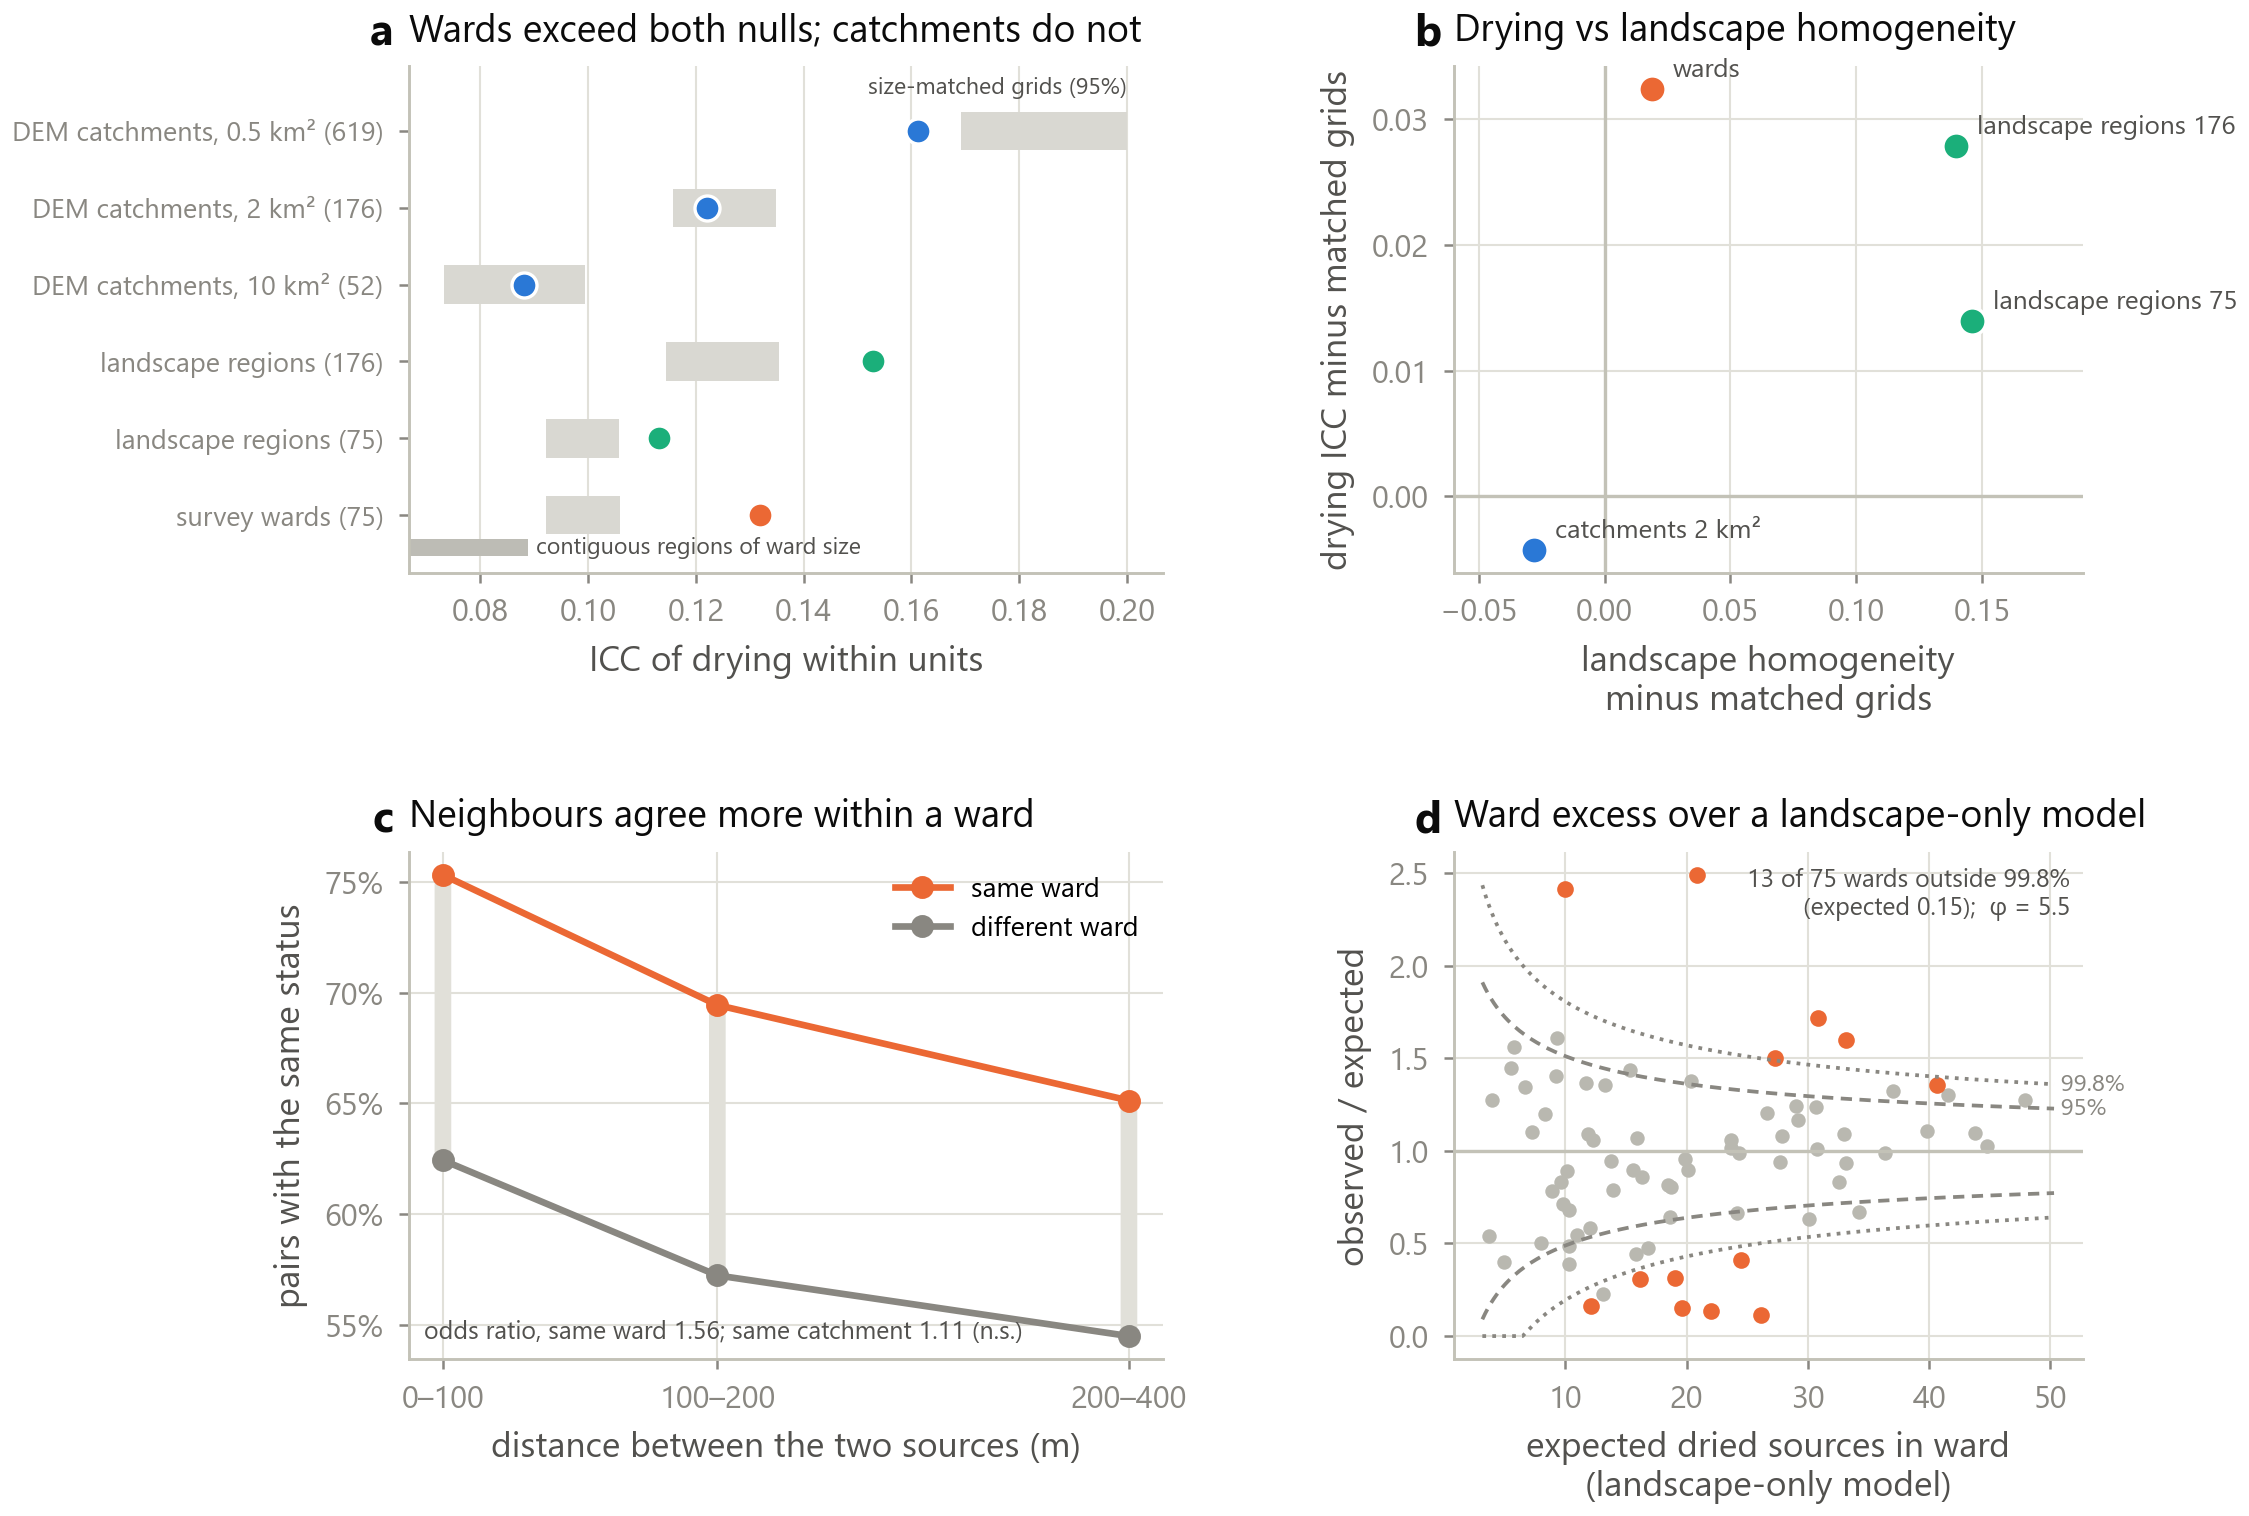

In [5]:
fig("fig5_wards_watersheds.png")